# Leaky Integrate-and-Fire (LIF) neuron from scratch

This notebook simulates a single **LIF neuron**, the basic building block of spiking neural networks. Run the cells from top to bottom.

**The idea in three lines**
1. An input current **charges** the membrane potential $V_{mem}$, like a capacitor.
2. A leak constantly pulls $V_{mem}$ back toward its resting value.
3. When $V_{mem}$ **crosses a threshold**, the neuron emits a **spike**, and $V_{mem}$ is **reset**.

$$\tau_m \frac{dV_{mem}}{dt} = -(V_{mem} - V_{rest}) + R\,I(t)$$

If $V_{mem} \ge V_{th}$: output a spike, set $V_{mem} = V_{reset}$, and stay silent for a short *refractory period*.

Units: time in ms, voltage in mV, current in nA, resistance in M$\Omega$ (so $R \cdot I$ comes out in mV).

## 0. Imports

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 3.2)
plt.rcParams["axes.grid"] = True

## 1. Neuron parameters

| Name | Value | Meaning |
|---|---|---|
| `V_rest` | -65 mV | resting potential, where the leak pulls $V_{mem}$ |
| `V_th` | -50 mV | spike threshold |
| `V_reset` | -65 mV | potential right after a spike |
| `tau` | 20 ms | membrane time constant (how fast it charges and leaks) |
| `R` | 10 M$\Omega$ | membrane resistance (how strongly current moves $V_{mem}$) |
| `t_ref` | 2 ms | refractory period (no spiking right after a spike) |
| `dt` | 0.1 ms | simulation time step |

The smallest current that can ever make the neuron fire  is $I_{th} = (V_{th}-V_{rest})/R$.

In [9]:
V_rest, V_th, V_reset = -65.0, -50.0, -65.0   # mV
tau, R, t_ref = 20.0, 10.0, 2.0               # ms, MOhm, ms
dt = 0.1                                      # ms

I_th = (V_th - V_rest) / R
print(f"Smallest current: {I_th:.2f} nA  (below this, the neuron can never fire)")

Smallest current: 1.50 nA  (below this, the neuron can never fire)


## 2. The LIF simulator

At every time step we do three things:

1. **Integrate:** $V \leftarrow V + \frac{dt}{\tau}\big(-(V - V_{rest}) + R\,I\big)$ (Euler method).
2. **Check the threshold:** if $V \ge V_{th}$, record a spike and reset $V$.
3. **Refractory:** for `t_ref` ms after a spike, hold $V$ at the reset value.

In [10]:
def simulate_lif(I, dt=dt):
    # I: array of input current (nA), one value per time step.
    # Returns membrane potential V (mV) and the array of spike times (ms).
    n = len(I)
    V = np.full(n, V_rest)
    spike_times = []
    refractory_left = 0.0

    for k in range(1, n):
        if refractory_left > 0:                       # just spiked: stay at reset
            V[k] = V_reset
            refractory_left -= dt
            continue

        dV = (-(V[k-1] - V_rest) + R * I[k-1]) / tau   # leak + input drive
        V[k] = V[k-1] + dt * dV                         # integrate

        if V[k] >= V_th:                                # threshold crossed
            spike_times.append(k * dt)                  # -> output spike
            V[k] = V_reset                              # reset
            refractory_left = t_ref
    return V, np.array(spike_times)

## 3. A step of input current



5 spikes at (ms): [ 47.7  77.4 107.1 136.8 166.5]


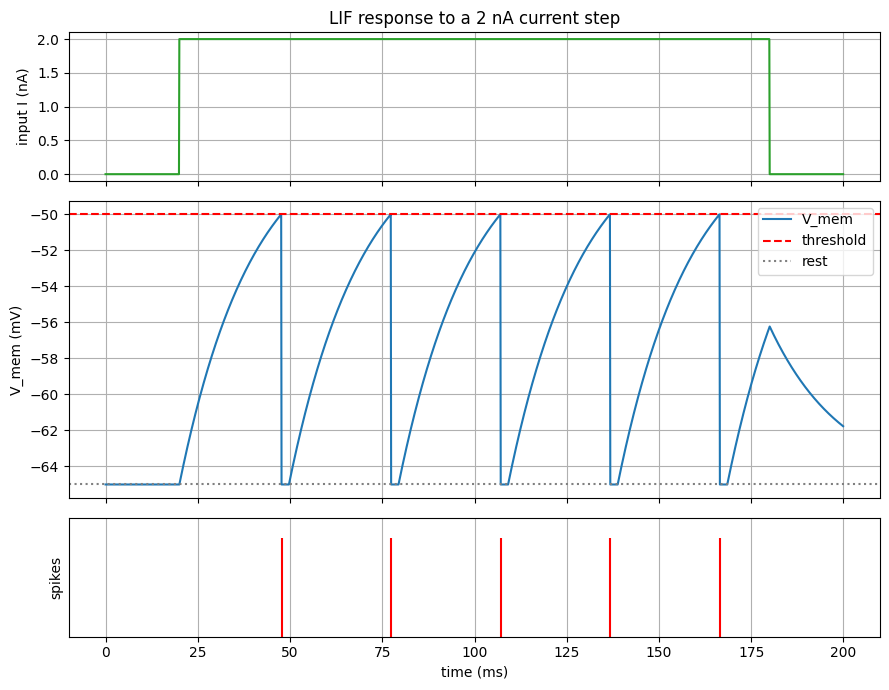

In [11]:
def plot_run(I, V, spikes, title):
    t = np.arange(len(I)) * dt
    fig, ax = plt.subplots(3, 1, figsize=(9, 7), sharex=True,
                           gridspec_kw={"height_ratios": [1, 2, 0.8]})
    ax[0].plot(t, I, color="tab:green"); ax[0].set_ylabel("input I (nA)")
    ax[0].set_title(title)

    ax[1].plot(t, V, label="V_mem")
    ax[1].axhline(V_th, color="r", ls="--", label="threshold")
    ax[1].axhline(V_rest, color="gray", ls=":", label="rest")
    ax[1].set_ylabel("V_mem (mV)"); ax[1].legend(loc="upper right")

    ax[2].vlines(spikes, 0, 1, color="r"); ax[2].set_ylim(0, 1.2)
    ax[2].set_yticks([]); ax[2].set_ylabel("spikes"); ax[2].set_xlabel("time (ms)")
    plt.tight_layout(); plt.show()

T = 200.0
n = int(T / dt)
t = np.arange(n) * dt

I_step = np.zeros(n)
I_step[(t >= 20) & (t < 180)] = 2.0

V, spikes = simulate_lif(I_step)
print(f"{len(spikes)} spikes at (ms):", np.round(spikes, 1))
plot_run(I_step, V, spikes, "LIF response to a 2 nA current step")

## 4. Weak, medium and strong input



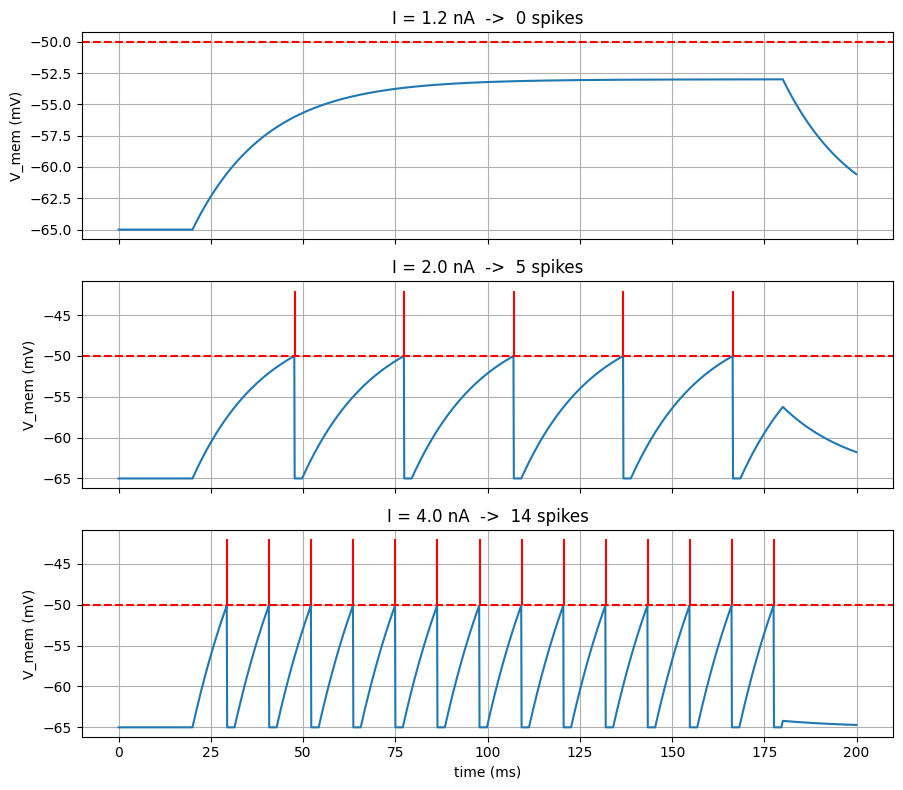

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, I_val in zip(axes, [1.2, 2.0, 4.0]):
    I = np.zeros(n); I[(t >= 20) & (t < 180)] = I_val
    V, sp = simulate_lif(I)
    ax.plot(t, V); ax.axhline(V_th, color="r", ls="--")
    ax.vlines(sp, V_th, V_th + 8, color="r")
    ax.set_ylabel("V_mem (mV)")
    ax.set_title(f"I = {I_val} nA  ->  {len(sp)} spikes")
axes[-1].set_xlabel("time (ms)"); plt.tight_layout(); plt.show()

## 5. A slowly increasing (ramp) input



First spike at 94.8 ms, when I = 1.90 nA (rheobase = 1.50 nA)


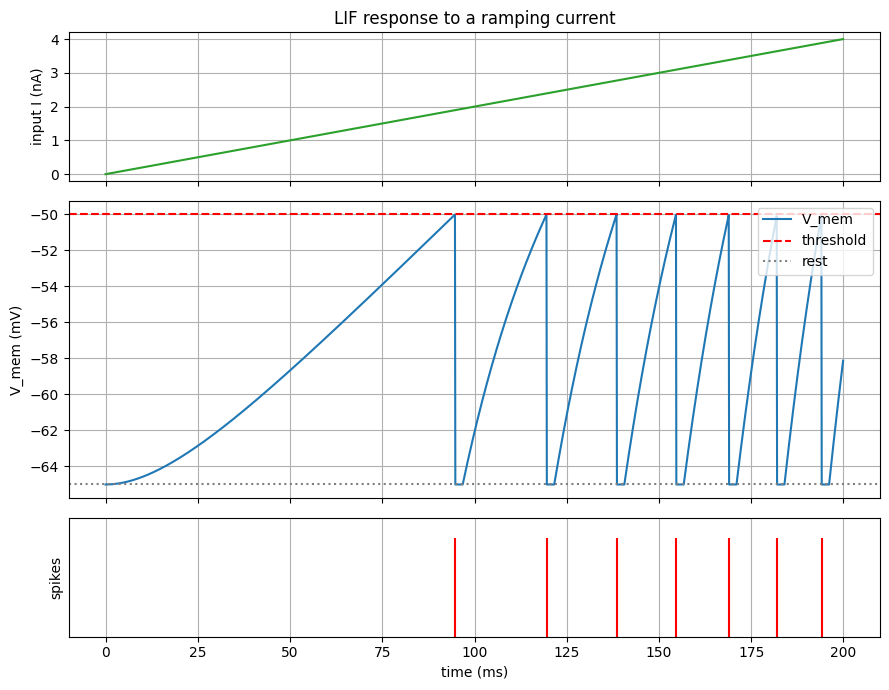

In [13]:
I_ramp = np.linspace(0, 4.0, n)
V, spikes = simulate_lif(I_ramp)
print(f"First spike at {spikes[0]:.1f} ms, when I = {I_ramp[int(spikes[0]/dt)]:.2f} nA "
      f"(rheobase = {I_rheobase:.2f} nA)")
plot_run(I_ramp, V, spikes, "LIF response to a ramping current")